# 02 · Phone Self-Checkout with Computer Vision: How Many Humans Does an "Automatic" Store Need?

**Author:** Juan Antonio Sainz Gálvez · Applied AI & ML, Conestoga College

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/02_vision_self_checkout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## Abstract

*GrabGo* is a self-checkout system I am deploying in small closed spaces (offices, warehouses and short-term rental homes). There is no special hardware: the owner's existing camera watches the shelf, the shopper photographs what they took with their own phone, an AI model builds the cart, and the shopper can correct it before paying. Every correction becomes training data.

Industry experience shows the hard part is not recognition accuracy on a benchmark but **how much human review the system needs in practice**. This notebook reviews research on automatic checkout, retail product recognition, vision-language models and active learning, and runs a reproducible experiment on an embedding-based recognizer that learns from shopper corrections. The question: **how should a store decide when to ask the shopper to confirm, so that wrong charges stay low without asking on every purchase?**


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})

def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="none"))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
            color=text_color, fontsize=fontsize, fontweight="bold", wrap=True)

def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


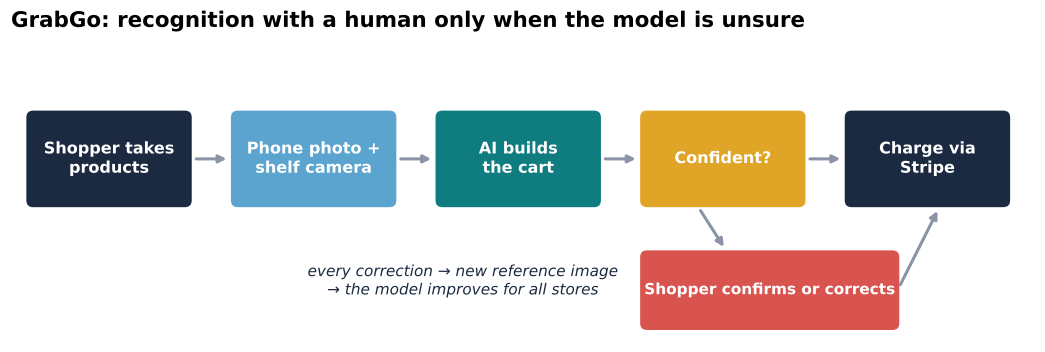

In [2]:
# Infographic: the GrabGo loop
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 3.6); ax.axis("off")
steps = [("Shopper takes\nproducts", PALETTE["navy"]), ("Phone photo +\nshelf camera", PALETTE["sky"]),
         ("AI builds\nthe cart", PALETTE["teal"]), ("Confident?", PALETTE["gold"]),
         ("Charge via\nStripe", PALETTE["navy"])]
for i, (t, c) in enumerate(steps):
    box(ax, (0.2 + i * 2.4, 1.6), 1.9, 1.1, t, c, fontsize=10.5)
    if i < len(steps) - 1:
        arrow(ax, (2.1 + i * 2.4, 2.15), (2.6 + i * 2.4, 2.15))
box(ax, (7.4, 0.15), 3.0, 0.9, "Shopper confirms or corrects", PALETTE["coral"], fontsize=10)
arrow(ax, (8.05, 1.6), (8.4, 1.05)); arrow(ax, (10.4, 0.6), (10.9, 1.6))
ax.text(5.3, 0.55, "every correction → new reference image\n→ the model improves for all stores",
        ha="center", fontsize=10, color=PALETTE["navy"], style="italic")
ax.set_title("GrabGo: recognition with a human only when the model is unsure", pad=6)
plt.show()

## 1. Literature review

### 1.1 Automatic checkout as a research problem
Wei et al. introduced the **RPC dataset** for automatic checkout [1]: 200 retail SKUs, 53,739 single-product exemplar images for training and 30,000 checkout images with up to 17 products each, in easy, medium and hard clutter levels. They frame the problem as large-scale, fine-grained, few-shot and cross-domain, because products change constantly and training images rarely look like real checkout scenes. Follow-up work on RPC raised checkout accuracy from 56.68% to 80.51% with data priming [2].

The **AI City Challenge** has run an automated retail checkout track since 2022, where teams detect and count products moving through a checkout area in video, trained mostly on synthetic data [3]. Typical solutions combine a YOLO detector with a tracker [4] and add correction steps such as retrospective checking of earlier detections to fix flickering results [5]. A survey of deep learning for retail product recognition lists the recurring challenges: many fine-grained classes, few examples per class, constant catalog changes and domain shift [6].

### 1.2 Vision-language models: recognizing new products without retraining
Because catalogs change, recent work moves from closed-set classifiers to **embedding-based retrieval**. RetailKLIP fine-tunes a CLIP vision encoder with metric learning so that new products are classified by nearest-neighbour search without retraining [7]. Tur et al. benchmark zero-shot classification of fine-grained retail products with CLIP, BLIP and DINOv2 on the MIMEX dataset and propose visual prototypes built from a few samples [8]. A 2026 study evaluates 190 open-source vision-language models on grocery product retrieval and finds that standard benchmarks fail to capture fine-grained SKU discrimination [9].

### 1.3 Humans in the loop: active learning and noisy corrections
Active learning reduces labeling effort by sending only the most informative samples to humans. In retail, it has been evaluated to cut annotation work for product recognition, which must be repeated whenever products change [10]. Real human corrections are noisy: Schubert et al. study active learning for object detection with a **noisy oracle** and show that reviewing suspected label errors beats both random review and no review [11]. Beck et al. go beyond labeling, combining auto-labeling, human correction and cheaper human *verification* [12].

### 1.4 The industry lesson
The best-known checkout-free system shows why this matters. According to reports in 2024, about 700 of every 1,000 Just Walk Out transactions in 2022 needed human review, against an internal target of 50 per 1,000; Amazon disputed the figures and said the India-based team mainly helped train the model [13]. Whatever the exact number, **the human review rate per 1,000 purchases is the metric that decides whether an "automatic" store is viable**.

**Gap.** Benchmarks report recognition accuracy on fixed datasets. Small stores need a policy that decides, purchase by purchase, when to ask the shopper, and that improves from the shopper's own corrections.


## 2. Experiment: confidence routing with learning from corrections

**Model.** Each product is a cluster in an embedding space (as a CLIP-style encoder would produce). The store owner uploads 5 catalog photos per product; the recognizer classifies a photo by cosine similarity to each product's prototype (the mean of its reference embeddings), as in [7, 8]. Some products come in **look-alike pairs** (same brand, different flavour), the fine-grained case that breaks recognizers [1, 9].

**Stream.** 60 days of purchases with 1–5 items each; on day 20 the owner adds 10 new products with only 3 photos each (catalog change).

**Policies**
1. **Static** — never asks, never learns.
2. **Confirm every cart** — the shopper confirms every purchase; corrections are added to the reference set.
3. **Confidence routing** — the shopper is asked only when the least-confident item's margin (top-1 minus top-2 similarity) is below a threshold τ; corrections are added.

Shoppers correct a wrong item 90% of the time (a noisy oracle, as in [11]). **Metrics:** wrong charges per 1,000 carts and shopper confirmations per 1,000 carts.


In [3]:
import numpy as np
import pandas as pd

RNG_SEED = 11
D, K_START, K_NEW, PAIRS = 64, 40, 10, 8
NOISE = 0.32          # lighting, angle and occlusion variability of real photos
LOOKALIKE = 0.50      # distance between look-alike products

def make_catalog(rng):
    means = rng.normal(size=(K_START + K_NEW, D))
    for i in range(PAIRS):                       # look-alike pairs among the starting products
        means[2 * i + 1] = means[2 * i] + LOOKALIKE * rng.normal(size=D)
    return means / np.linalg.norm(means, axis=1, keepdims=True)

def photo(rng, means, k):
    v = means[k] + NOISE * rng.normal(size=D) / np.sqrt(D) * 4
    return v / np.linalg.norm(v)

class Recognizer:
    """Nearest-prototype recognizer over a growing reference set (prototype = mean of reference embeddings)."""
    def __init__(self):
        self.keys, self.sums, self.counts = [], [], []
    def add(self, k, v):
        if k not in self.keys:
            self.keys.append(k); self.sums.append(np.zeros(D)); self.counts.append(0)
        i = self.keys.index(k); self.sums[i] = self.sums[i] + v; self.counts[i] += 1
    def predict(self, v):
        protos = np.array(self.sums)
        protos /= np.linalg.norm(protos, axis=1, keepdims=True)
        s = protos @ v
        top2 = np.argsort(s)[-2:]
        return self.keys[top2[1]], s[top2[1]] - s[top2[0]]

print("embedding dim:", D, "| products:", K_START, "+", K_NEW, "new on day 20 | look-alike pairs:", PAIRS)

embedding dim: 64 | products: 40 + 10 new on day 20 | look-alike pairs: 8


In [4]:
def run(policy, tau=0.05, seed=RNG_SEED, days=60, carts_per_day=60, oracle=0.9):
    rng = np.random.default_rng(seed)
    means = make_catalog(rng)
    rec = Recognizer()
    for k in range(K_START):
        for _ in range(5):
            rec.add(k, photo(rng, means, k))
    rows = []
    for day in range(days):
        if day == 20:
            for k in range(K_START, K_START + K_NEW):
                for _ in range(3):
                    rec.add(k, photo(rng, means, k))
        live = K_START + (K_NEW if day >= 20 else 0)
        for _ in range(carts_per_day):
            items = rng.integers(0, live, size=rng.integers(1, 6))
            shots = [photo(rng, means, k) for k in items]
            preds = [rec.predict(v) for v in shots]
            min_margin = min(m for _, m in preds)
            ask = policy == "confirm_every_cart" or (policy == "confidence_routing" and min_margin < tau)
            wrong = [p != k for (p, _), k in zip(preds, items)]
            if ask:
                fixed = [w and rng.random() < oracle for w in wrong]
                charged_wrong = any(w and not f for w, f in zip(wrong, fixed))
                for v, (p, _), k, w, f in zip(shots, preds, items, wrong, fixed):
                    rec.add(k if (not w or f) else p, v)   # unfixed errors pollute the reference set
            else:
                charged_wrong = any(wrong)
            rows.append(dict(day=day, asked=ask, wrong_charge=charged_wrong, item_errors=sum(wrong)))
    return pd.DataFrame(rows).assign(policy=policy)

runs = pd.concat([run("static"), run("confirm_every_cart"), run("confidence_routing")])
table = (runs.groupby("policy")
             .agg(wrong_charges_per_1000=("wrong_charge", lambda s: 1000 * s.mean()),
                  confirmations_per_1000=("asked", lambda s: 1000 * s.mean()))
             .round(1).loc[["static", "confirm_every_cart", "confidence_routing"]])
table

,wrong_charges_per_1000,confirmations_per_1000
policy,,
static,248.6,0.0
confirm_every_cart,11.4,1000.0
confidence_routing,15.6,420.8


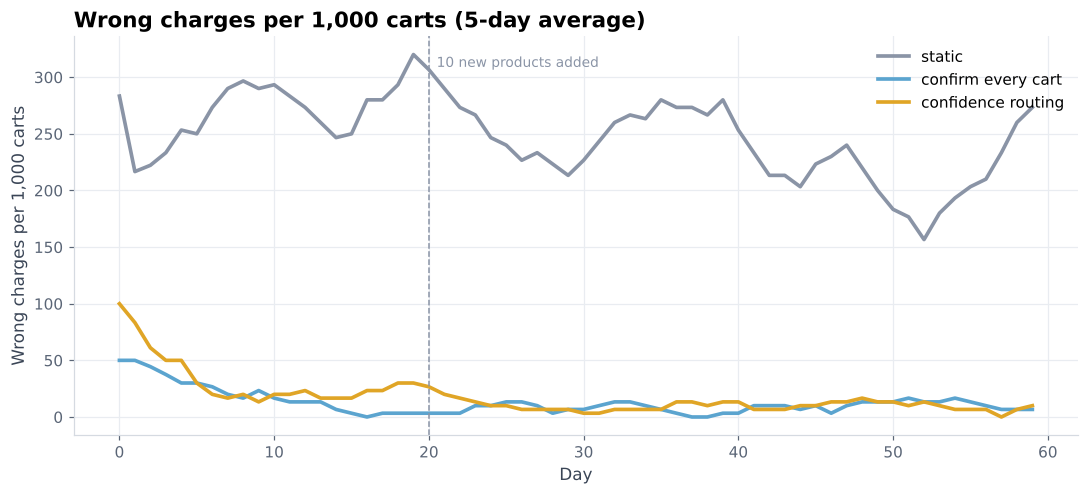

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for (p, g), c in zip(runs.groupby("policy", sort=False), POLICY_COLORS):
    w = g.groupby("day").wrong_charge.mean().rolling(5, min_periods=1).mean() * 1000
    ax.plot(w.index, w.values, lw=2.4, label=p.replace("_", " "))
ax.axvline(20, color=PALETTE["grey"], ls="--", lw=1)
ax.text(20.5, ax.get_ylim()[1] * 0.92, "10 new products added", color=PALETTE["grey"], fontsize=9)
ax.set_title("Wrong charges per 1,000 carts (5-day average)")
ax.set_xlabel("Day"); ax.set_ylabel("Wrong charges per 1,000 carts"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### Choosing the threshold
The threshold τ is the business decision: higher τ asks shoppers more often and charges wrong less often. The frontier below shows every option, with the industry reference points of 50 and 700 human reviews per 1,000 purchases from [13].


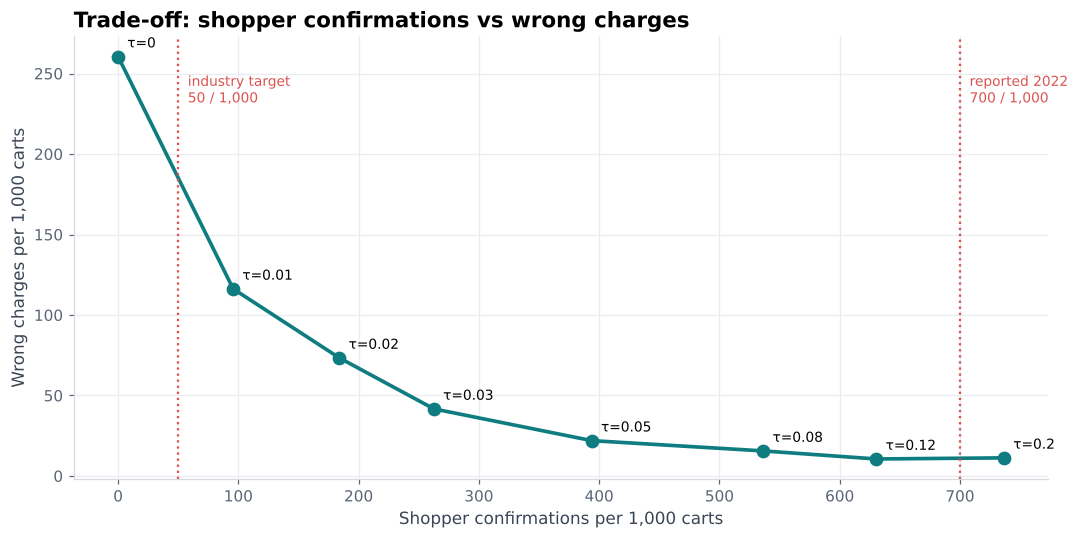

,tau,confirmations,wrong
0,0.00,0.0,260.6
1,0.01,95.7,116.2
2,0.02,184.0,73.3
3,0.03,262.6,41.7
4,0.05,393.9,21.9
5,0.08,536.5,15.6
6,0.12,630.6,10.6
7,0.20,736.7,11.2


In [6]:
taus = [0.0, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2]
frontier = []
for t in taus:
    r = pd.concat([run("confidence_routing", tau=t, seed=s, days=40) for s in range(3)])
    frontier.append(dict(tau=t, confirmations=1000 * r.asked.mean(), wrong=1000 * r.wrong_charge.mean()))
frontier = pd.DataFrame(frontier)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(frontier.confirmations, frontier.wrong, "-o", color=PALETTE["teal"], lw=2.4, ms=8)
for _, r in frontier.iterrows():
    ax.annotate(f"τ={r.tau:g}", (r.confirmations, r.wrong), textcoords="offset points", xytext=(6, 6), fontsize=9)
for x, label in [(50, "industry target\n50 / 1,000"), (700, "reported 2022\n700 / 1,000")]:
    ax.axvline(x, color=PALETTE["coral"], ls=":", lw=1.5)
    ax.text(x + 8, ax.get_ylim()[1] * 0.85, label, color=PALETTE["coral"], fontsize=9)
ax.set_title("Trade-off: shopper confirmations vs wrong charges")
ax.set_xlabel("Shopper confirmations per 1,000 carts"); ax.set_ylabel("Wrong charges per 1,000 carts")
plt.tight_layout(); plt.show()
frontier.round({"tau": 3, "confirmations": 1, "wrong": 1})

## 3. Discussion

- **Static recognition is not usable.** Without asking or learning, roughly one cart in four is charged wrong, almost all because of look-alike products. Benchmark accuracy on ordinary products (about 99% here) hides this.
- **Confirming every cart** gives the fewest wrong charges (about 11 per 1,000) but asks on every purchase, which defeats the purpose of a fast checkout.
- **Confidence routing** reaches almost the same wrong-charge rate (about 16 per 1,000 at τ = 0.05) while asking on only about 4 carts in 10. Wrong charges fall over the first weeks (about 32 per 1,000 in days 0–9, about 8–12 later) because the corrections it collects are exactly the hard cases.
- **But the confirmation rate does not fall.** It stays near 400 per 1,000: look-alike products remain close in embedding space no matter how many reference photos are added, so their margin stays low. Better prototypes alone cannot reach the 50 per 1,000 target; the system needs **new information** (a second view, the shelf camera, the inventory count), which motivates thesis question 1.
- **Noisy corrections matter.** When a shopper does not fix an error, the wrong label enters the reference set and can make later mistakes more likely, as studied in [11]. In a real deployment this argues for a second check before a correction is trusted.

**Limitations.** Embeddings here are simulated Gaussian clusters, not photos; real errors are correlated (lighting, a dirty lens, a product facing backwards). The next step is to replay real GrabGo photos and corrections through the same policies.

## 4. Thesis questions

1. **Multi-agent verification of a cart.** The phone photo, the shelf camera and the inventory count are three independent "witnesses". Can an agent that reconciles them decide when a human is needed better than a single confidence score?
2. **Trusting shopper corrections.** How should a store weigh a correction by its source (shopper history, agreement with the camera) to avoid polluting the reference set?
3. **Federated learning across stores.** Each store sees different products and lighting. Can stores share what they learn without sharing their customers' images?

## References

1. Wei, X.-S., Cui, Q., Yang, L., Wang, P., & Liu, L. (2019). *RPC: A Large-Scale Retail Product Checkout Dataset.* arXiv:1901.07249.
2. Li, C., Du, D., et al. (2019). *Data Priming Network for Automatic Check-Out.* ACM Multimedia 2019. arXiv:1904.04978.
3. Naphade, M., et al. (2023). *The 7th AI City Challenge.* CVPR Workshops. arXiv:2304.07500.
4. Shoman, M., Aboah, A., et al. (2022). *A Region-Based Deep Learning Approach to Automated Retail Checkout.* CVPR Workshops.
5. Cai, Y., & Jiao, A. (2023). *DACNet: A Deep Automated Checkout Network with Selective Deblurring.* CVPR Workshops.
6. Wei, Y., Tran, S. N., Xu, S., Kang, B. H., & Springer, M. (2020). *Deep Learning for Retail Product Recognition: Challenges and Techniques.* Computational Intelligence and Neuroscience.
7. *RetailKLIP: Finetuning OpenCLIP backbone using metric learning on a single GPU for zero-shot retail product image classification* (2023). arXiv:2312.10282.
8. Tur, A. O., Conti, A., et al. (2024). *Exploring Fine-grained Retail Product Discrimination with Zero-shot Object Classification Using Vision-Language Models.* IEEE RTSI 2024. arXiv:2409.14963.
9. Maminta, E. G., & Atienza, R. O. (2026). *What Matters for Grocery Product Retrieval with Open Source Vision Language Models.* arXiv:2605.18029.
10. *Active learning to minimize annotation effort for retail product recognition* (2024). Journal of Computational Social Science, doi:10.1007/s42001-024-00266-7.
11. Schubert, M., Riedlinger, T., Kahl, K., & Rottmann, M. (2024). *Deep Active Learning with Noisy Oracle in Object Detection.* VISAPP 2024. arXiv:2310.00372.
12. Beck, N., Killamsetty, K., et al. (2023). *Beyond Active Learning: Leveraging the Full Potential of Human Interaction via Auto-Labeling, Human Correction, and Human Verification.* arXiv:2306.01277.
13. Business Insider and The Information (April 2024), reporting on Amazon Just Walk Out human review rates; Amazon disputed the figures.
